# Oil products demand — 01 Data pipeline: US jet fuel

**Purpose.** Take two public sources from their raw files to one point-in-time modelling dataset: US jet fuel demand as EIA measures it, and a physical indicator readable the next day, the kerosene burned by the commercial jets that leave US airports, computed flight by flight from the ADS-B record of the OpenSky Network. Show for every variable where it comes from, how it was processed and from when it could legitimately be used. `02_model_jet.ipynb` only reads the tables this pipeline writes.

**Run order.** `python -m src.download` (optional; `opensky` needs a Trino account) → this notebook → `01_data_naphtha.ipynb` → `python -m src.model` (the backtests, about an hour) → `02_model_jet.ipynb`. The two build cells below are the same as `python -m src.sql` and `python -m src.data`.

| Step | Where | Output |
|---|---|---|
| Ingestion | `src/download.py`, `src/flights.py` | `data/US_jet_fuel/eia_*.csv`, `aircraft.csv`, `fuel_table.csv`, `opensky/*.csv` |
| Raw layer | `src/sql.py` | DuckDB table `raw`: every observation, every vintage seen |
| Clean layer | `src/sql.py` | DuckDB tables `demand`, `predictors`, `catalog` |
| Alignment | `src/data.py` | DuckDB table `panel`, read by `src/model.py` and notebook 02 |

**State of the burn index.** OpenSky's Trino database needs an account, requested and not yet granted at the time of this run. Everything that does not depend on it is built and tested here: the aircraft types, the OpenAP fuel table, the distances, the query, the treatment of lost days. The index itself, and every check that needs it, waits for the access (section 9).

In [1]:
import sys
sys.path.insert(0, "..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import config as c, data, flights, sql

pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.width", 250)
pd.set_option("display.max_colwidth", None)
plt.rcParams.update({"figure.figsize": (10, 3), "axes.grid": True, "grid.alpha": .3})

## 1. Ingestion: raw files into DuckDB

`sql.build()` appends to `raw` whatever the files hold that the table does not: new observations and revised values, each stamped with `ingested_at`, the time its file was downloaded. Nothing is ever updated or deleted, so the load is idempotent and a revision is kept next to the value it replaces. It loads the files of every product.

In [2]:
sql.build()

      0 rows added to raw from US_jet_fuel/eia_monthly.csv
      0 rows added to raw from US_jet_fuel/eia_weekly.csv
  1,233 rows added to raw from KR_JP_naphtha/jodi.csv
      0 rows added to raw from KR_JP_naphtha/customs.csv


In [3]:
sql.build()  # a second run adds nothing

      0 rows added to raw from US_jet_fuel/eia_monthly.csv
      0 rows added to raw from US_jet_fuel/eia_weekly.csv
      0 rows added to raw from KR_JP_naphtha/jodi.csv
      0 rows added to raw from KR_JP_naphtha/customs.csv


In [4]:
sql.query("DESCRIBE raw")[["column_name", "column_type"]]

,column_name,column_type
0,file,VARCHAR
1,series,VARCHAR
2,obs_date,DATE
3,value,DOUBLE
4,ingested_at,TIMESTAMP


In [5]:
# what entered from the jet files, and when
sql.query("""
    SELECT file, CAST(MAX(ingested_at) AS DATE) AS ingested, COUNT(DISTINCT series) AS series, COUNT(*) AS observations,
           MIN(obs_date) AS first_date, MAX(obs_date) AS last_date
    FROM raw WHERE file LIKE 'US_jet_fuel/%' GROUP BY 1 ORDER BY 1
""")

,file,ingested,series,observations,first_date,last_date
0,US_jet_fuel/eia_monthly.csv,2026-11-19,1,740,1965-01-15,2026-08-15
1,US_jet_fuel/eia_weekly.csv,2026-11-19,1,1867,1991-02-08,2026-11-13


## 2. Sources and conventions

`catalog` is the data dictionary, stored next to the data. The publication lag is the one number the model depends on; it lives in `config.py` and is added here.

In [6]:
catalog = sql.query("SELECT * FROM catalog WHERE product = 'jet'")
catalog[["variable", "source", "source_id", "definition", "unit", "frequency", "date_stamp", "release"]]

,variable,source,source_id,definition,unit,frequency,date_stamp,release
0,demand,EIA Petroleum Supply Monthly,MKJUPUS2,Kerosene-type jet fuel product supplied,kb/d,monthly,15th of the month,end of the second month after
1,product_supplied_weekly,EIA Weekly Petroleum Status Report,WKJUPUS2,Kerosene-type jet fuel product supplied (weekly estimate; context only),kb/d,weekly,Friday ending the week,Wednesday after the week
2,burn,OpenSky Network flights_data4 with OpenAP,flights_data4 + aircraft database,Fuel burned by commercial jets leaving US airports (28-day mean),kb/d,daily,UTC day the flight ended,the next day
3,flights,OpenSky Network flights_data4,flights_data4,Departures of commercial jets from US airports (coverage; context only),flights,daily,UTC day the flight ended,the next day
4,unknown_airport,OpenSky Network flights_data4,flights_data4,Share of the flights the index could count that lack an estimated airport (coverage; context only),share,daily,UTC day the flight ended,the next day


In [7]:
pd.DataFrame({"lag": {"demand": f"{c.DEMAND_LAG['jet']} months", "product_supplied_weekly": f"{c.WEEKLY_LAG_DAYS} days (context)",
                      "burn": f"{c.BURN_LAG_DAYS} day"}})

,lag
demand,2 months
product_supplied_weekly,6 days (context)
burn,1 day


- **EIA.** The target is kerosene-type jet fuel product supplied from the Petroleum Supply Monthly (`MKJUPUS2`), in kb/d, published at the end of the second month after. The weekly figure of the Weekly Petroleum Status Report (`WKJUPUS2`) is the same concept a week after the fact: it is kept as the yardstick the burn index has to beat, not as a feature.
- **OpenSky Network.** Every flight its receivers closed on a UTC day, with estimated departure and arrival airports (`flights_data4`, from 2016), joined to OpenSky's aircraft database for the type. Section 9 turns them into the index.

Four dates are kept apart throughout:

- **Observation date** — `period_end`, the last day of the period the number describes: a month, a week, a day.
- **Availability date** — `available_at`, when the number was published: `period_end` plus the source's lag. This is the date every join uses.
- **Ingestion date** — `ingested_at`, when the file entered this database.
- **Vintage** — which version of a revised number. EIA publishes only its latest version, so the database holds vintages only from its first download on (section 5).

## 3. Clean layer

`demand` and `predictors` are rebuilt from the latest value of every raw observation. Cleaning is limited to standardisation: one date convention (`period_end`), one name per variable. No value is filled, smoothed or removed.

In [8]:
sql.query("SELECT product, unit, MIN(period_end) AS first, MAX(period_end) AS last, COUNT(*) AS months FROM demand WHERE product = 'jet' GROUP BY 1, 2")

,product,unit,first,last,months
0,jet,kb/d,1965-01-31,2026-08-31,740


In [9]:
sql.query("SELECT variable, MIN(period_end) AS first, MAX(period_end) AS last, COUNT(*) AS observations FROM predictors WHERE product = 'jet' GROUP BY 1 ORDER BY 1")

,variable,first,last,observations
0,product_supplied_weekly,1991-02-08,2026-11-13,1867


## 4. Validation of the clean tables

In [10]:
# keys, missing values, impossible values, over the sample the model uses (2000 on)
sql.query(f"""
    SELECT 'demand' AS table_name, COUNT(*) AS rows, COUNT(*) - COUNT(DISTINCT (product, period_end)) AS duplicates,
           COUNT(*) FILTER (WHERE value IS NULL) AS missing, COUNT(*) FILTER (WHERE value <= 0) AS not_positive
    FROM demand WHERE product = 'jet' AND period_end >= DATE '{c.SAMPLE_START}'
    UNION ALL
    SELECT 'predictors', COUNT(*), COUNT(*) - COUNT(DISTINCT (product, variable, period_end)),
           COUNT(*) FILTER (WHERE value IS NULL), COUNT(*) FILTER (WHERE value <= 0)
    FROM predictors WHERE product = 'jet' AND period_end >= DATE '{c.SAMPLE_START}'
""")

,table_name,rows,duplicates,missing,not_positive
0,demand,320,0,0,0
1,predictors,1402,0,0,0


In [11]:
# frequency: days between consecutive observations of each series, since 2000
gaps = sql.query("""
    SELECT variable, period_end, period_end - LAG(period_end) OVER (PARTITION BY variable ORDER BY period_end) AS gap_days
    FROM (SELECT variable, period_end FROM predictors WHERE product = 'jet' UNION ALL SELECT 'demand', period_end FROM demand WHERE product = 'jet')
    WHERE period_end >= DATE '2000-01-01'
""")
gaps.groupby("variable")["gap_days"].agg(["median", "max"])

,median,max
variable,,
demand,31.00,31
product_supplied_weekly,7.00,7


In [12]:
# suspicious values: the largest month-on-month moves of the target, in %
moves = sql.query("""
    SELECT period_end, value, 100 * (value / LAG(value) OVER (ORDER BY period_end) - 1) AS move_pct
    FROM demand WHERE product = 'jet' AND period_end >= DATE '2000-01-01'
""")
moves.loc[moves["move_pct"].abs().nlargest(6).index].sort_values("period_end")

,period_end,value,move_pct
36,2003-01-31,"1,505.00",-12.60
61,2005-02-28,"1,743.00",13.48
242,2020-03-31,"1,388.00",-14.27
243,2020-04-30,678.00,-51.15
245,2020-06-30,784.00,31.32
246,2020-07-31,968.00,23.47


In [13]:
# cross-check between two EIA products: the weekly estimate averaged over each month against the monthly
# figure published two months later, absolute gap in %
check = sql.query("""
    SELECT d.period_end, d.value AS monthly, w.weekly
    FROM demand d
    JOIN (SELECT last_day(period_end) AS period_end, AVG(value) AS weekly
          FROM predictors WHERE product = 'jet' AND variable = 'product_supplied_weekly' GROUP BY 1) w USING (period_end)
    WHERE d.product = 'jet' AND d.period_end >= DATE '2000-01-01'
""")
check["gap_pct"] = 100 * (check["weekly"] / check["monthly"] - 1).abs()
check["gap_pct"].describe()[["count", "mean", "50%", "max"]].to_frame("weekly vs monthly, % gap").T

,count,mean,50%,max
"weekly vs monthly, % gap",320.00,2.87,2.49,12.43


VALIDATION

## 5. Point-in-time: publication lags and revisions

**Lags.** A number cannot be used before it is published. Each series gets `available_at = period_end + lag`, with the lag read off the source's release calendar (section 2): two month ends for the monthly target, the day after for the burn index.

**Are the lags right?** They can be tested against a real download. At the time of the latest ingestion, the convention says which period of each series should already be published; the file says which period actually was. The convention must never be ahead of the file.

In [14]:
ingested = sql.query("SELECT MAX(ingested_at) AS t FROM raw WHERE file LIKE 'US_jet_fuel/eia%'")["t"].iloc[0]
origin = ingested.normalize() - pd.offsets.MonthEnd(1)  # the last month end before the download
newest = sql.query("SELECT MAX(period_end) AS newest FROM demand WHERE product = 'jet'")["newest"].iloc[0]
allowed = origin - pd.offsets.MonthEnd(c.DEMAND_LAG["jet"])
weekly = sql.query("SELECT MAX(period_end) AS newest FROM predictors WHERE product = 'jet' AND variable = 'product_supplied_weekly'")["newest"].iloc[0]
assert newest >= allowed and weekly + pd.Timedelta(days=c.WEEKLY_LAG_DAYS) <= ingested
print(f"downloaded {ingested:%d %b %Y}, forecast origin {origin:%d %b %Y}: the convention allows demand to {allowed:%B %Y}, "
      f"the file holds {newest:%B %Y}; the newest week ends {weekly:%d %b %Y}")

downloaded 19 Nov 2026, forecast origin 31 Oct 2026: the convention allows demand to August 2026, the file holds August 2026; the newest week ends 13 Nov 2026


LAGS

**Revisions.** A lag stops a number from being used before it existed. It does not undo the fact that today's file shows the number as later revised. EIA publishes only its latest figures, so the dataset is built from current values: **publication delays are handled, revisions are not**.

In [15]:
sql.query("""
    SELECT file, COUNT(DISTINCT ingested_at) AS downloads, COUNT(*) FILTER (WHERE vintages > 1) AS revised_observations
    FROM latest WHERE file LIKE 'US_jet_fuel/%' GROUP BY 1 ORDER BY 1
""")

,file,downloads,revised_observations
0,US_jet_fuel/eia_monthly.csv,1,0
1,US_jet_fuel/eia_weekly.csv,1,0


REVISIONS

## 6. Alignment

Every driver is joined to a complete monthly index. A row for month *t* is a forecast origin: what was published by the last day of *t*. The join is `merge_asof(direction="backward")` on `available_at`, with a tolerance of `STALE_DAYS` days past which a value is left missing rather than carried. The burn index is daily: at the end of month *t* the newest day readable is the one before, so a row carries the mean of the 28 days to the day before its month end, the way EIA itself reports its weekly figures as four-week averages.

In [16]:
panel = data.align("jet")
print(f"{len(panel)} rows in the jet panel, drivers: {sorted(panel['variable'].unique()) if len(panel) else 'none yet'}")

0 rows in the jet panel, drivers: none yet


ALIGNMENT

## 7. Validation after alignment

A backward join guarantees that `available_at` is not later than the origin. It is only as good as `available_at` itself, which is why the lags were tested in section 5. The assertions below are the conditions the model relies on; they run on whatever the panel holds.

In [17]:
matched = panel.dropna(subset="value")
age = (matched["month_end"] - matched["period_end"]).dt.days
# no look-ahead: every value on a row was published by the row's month end, and describes a period that had ended
assert (matched["available_at"] <= matched["month_end"]).all()
assert (matched["period_end"] <= matched["month_end"]).all()
# no stale value: nothing older than the tolerance was carried forward
assert (age <= c.STALE_DAYS).all()
assert not panel.duplicated(["product", "variable", "month"]).any()

In [18]:
# the target obeys the same rule inside the model: at origin t the newest demand print is t minus its lag
jet = data.demand("jet")
pd.DataFrame({"demand": jet["demand"], "newest print at the origin": jet["demand"].shift(c.DEMAND_LAG["jet"])}).tail(3)

,demand,newest print at the origin
month,,
2026-06-01,"1,817.00","1,814.00"
2026-07-01,"1,890.00","1,706.00"
2026-08-01,"1,797.00","1,817.00"


## 8. Final dataset

`data.build()` stores the aligned panel of every product. `data.dataset("jet")` reads it back as the modelling frame: demand, then every driver as readable at that month end.

In [19]:
data.build()

,product,drivers,first,last,rows
0,naphtha_jp,1,2000-01-01,2026-11-01,323
1,naphtha_kr,1,2000-01-01,2026-11-01,323


In [20]:
df = data.dataset("jet")
pd.Series({"rows": len(df), "drivers": df.shape[1] - 1, "first": df.index.min(), "last origin": df.index.max(),
           "last demand": df["demand"].last_valid_index()}).to_frame("jet").T

,rows,drivers,first,last origin,last demand
jet,322,0,2000-01-01 00:00:00,2026-10-01 00:00:00,2026-08-01 00:00:00


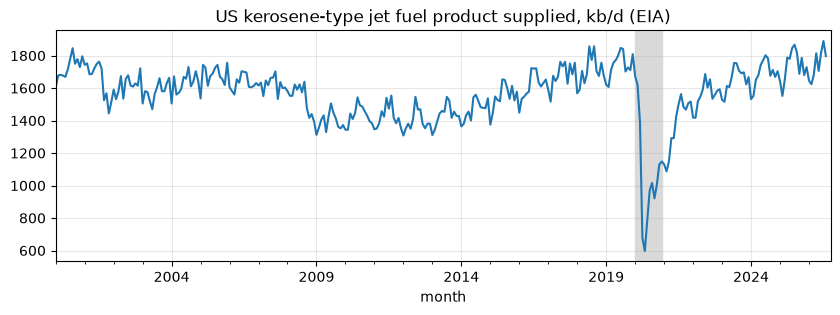

In [21]:
ax = df["demand"].plot(title="US kerosene-type jet fuel product supplied, kb/d (EIA)")
ax.axvspan(pd.Timestamp(c.COVID[0]), pd.Timestamp(c.COVID[1]), color="0.85"); ax.set_xlabel("month");

**What this dataset is and is not.**

- Every value was published by the month end of its row, under release-calendar lags that a real download confirms are not too short.
- It is **not** a vintage dataset. Values are today's, including later revisions.
- Until OpenSky grants the access, the jet dataset holds no driver: the model can only be run on lagged demand, which is the benchmark the burn index will be judged against.

## 9. The kerosene burn index

**The query.** One UTC day per query, filtered on the `day` partition, the flights that leave or reach an airport whose ICAO code starts with K, PA or PH. Queries run one at a time, under OpenSky's limit of two. The login stays in pyopensky's own settings file.

In [22]:
print(flights.query("2025-07-01"))

SELECT icao24, estdepartureairport, estarrivalairport FROM flights_data4 WHERE day = 1751328000 AND (estdepartureairport LIKE 'K%' OR estdepartureairport LIKE 'PA%' OR estdepartureairport LIKE 'PH%' OR estarrivalairport LIKE 'K%' OR estarrivalairport LIKE 'PA%' OR estarrivalairport LIKE 'PH%')


In [23]:
# the days that touch a window OpenSky lost for good: they will be missing, not zero
lost = sorted({d for start, end in c.OPENSKY_OUTAGES for d in pd.date_range(pd.Timestamp(start).normalize(), pd.Timestamp(end).normalize())})
pd.Series([d.strftime("%Y-%m-%d") for d in lost], name="days missing").to_frame().T

,0,1,2,3,4,5,6,7,8,9,...,11,12,13,14,15,16,17,18,19,20
days missing,2023-01-02,2023-01-03,2023-01-18,2023-01-19,2023-01-20,2023-01-21,2023-01-22,2023-01-23,2023-06-21,2023-11-15,...,2023-11-20,2023-12-02,2023-12-03,2023-12-04,2023-12-05,2024-05-20,2024-05-21,2026-01-02,2026-01-03,2026-01-24


**The types.** `flights_data4` gives no aircraft type. The type is joined on the transponder address `icao24` from OpenSky's aircraft database, one snapshot (August 2025) used for every year. Only the commercial jets of `config.COMMERCIAL_JETS` are kept, each mapped to an OpenAP model.

In [24]:
aircraft = pd.read_csv(c.JET / "aircraft.csv", dtype=str)
fleet = aircraft["typecode"].value_counts().rename("aircraft").to_frame()
fleet["OpenAP model"] = fleet.index.map(c.COMMERCIAL_JETS)
fleet["proxy"] = fleet.index.str.lower() != fleet["OpenAP model"]
print(f"{len(aircraft):,} commercial jets in the database, {fleet['proxy'].mul(fleet['aircraft']).sum() / fleet['aircraft'].sum():.0%} of them burned through a proxy")
fleet.head(12)

43,760 commercial jets in the database, 6% of them burned through a proxy


,aircraft,OpenAP model,proxy
typecode,,,
B738,6781,b738,False
A320,6184,a320,False
A20N,2501,a20n,False
A321,2234,a321,False
A21N,2003,a21n,False
B38M,1852,b38m,False
A319,1842,a319,False
B737,1410,b737,False
B763,1063,b763,False


**The fuel table.** For each OpenAP model, a complete flight (climb, cruise, descent) for each cruise range, integrated every 30 seconds with the mass falling from 85% of MTOW as fuel is burned. A flight shorter than the shortest complete one, about 650 km, is read on a line from zero.

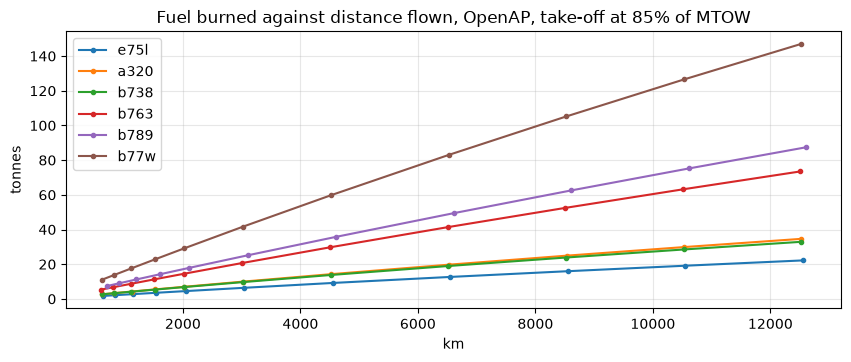

In [25]:
table = pd.read_csv(flights.FUEL_TABLE)
fig, ax = plt.subplots(figsize=(10, 3.6))
for model in ["e75l", "a320", "b738", "b763", "b789", "b77w"]:
    curve = table[table["model"] == model]
    ax.plot(curve["km"], curve["fuel_kg"] / 1000, marker="o", ms=3, label=model)
ax.set_title("Fuel burned against distance flown, OpenAP, take-off at 85% of MTOW"); ax.set_xlabel("km"); ax.set_ylabel("tonnes"); ax.legend();

In [26]:
# a unit check by hand: an A320 from New York JFK to Los Angeles
km = flights.distance(pd.Series(["KJFK"]), pd.Series(["KLAX"]))[0]
curve = table[table["model"] == "a320"]
fuel = np.interp(km, [0, *curve["km"]], [0, *curve["fuel_kg"]])  # as flights.burn reads the table
pd.Series({"great circle, km": km, "fuel, kg": fuel, "kg per km": fuel / km, "barrels": fuel / c.KG_PER_BARREL})

great circle, km    3,972.21
fuel, kg           12,677.88
kg per km               3.19
barrels                99.67
dtype: float64

UNITCHECK

**What waits for the access.** With OpenSky's Trino account, `python -m src.download opensky` fills `data/US_jet_fuel/opensky/`, one file a month of daily totals by type, and this section then shows: the index against EIA month by month and its ratio, which should be stable outside 2020; the days lost and how the 28-day mean bridges them; and the coverage drift, the share of flights OpenSky left without a departure or arrival airport, year by year. None of it is shown before the data exist.